# Prosopis Invasion & LULC Change — Baringo, Kenya (basic reproduction)

Reproduces the core pipeline of **Mbaabu et al. 2019**, *"Spatial Evolution of
Prosopis Invasion and its Effects on LULC and Livelihoods in Baringo, Kenya"*
(*Remote Sensing* 11(10):1217), in Python instead of R, with a scikit-learn
Random Forest instead of R's `randomForest`, and one added twist: a **current**
time step so you can see how far the invasion has moved since 2016.

**What this notebook reproduces faithfully:**
- Dry+wet season Landsat composites, stacked with NDVI (both seasons) + SRTM elevation — the same 15-band feature stack the paper used, and for the same reason: Prosopis is evergreen, the native *Vachellia* is deciduous, so the dry-season contrast is what actually separates them spectrally.
- Random Forest classification, 1000 trees, default `mtry`/`max_features` — same as the paper.
- The same change-detection outputs: per-class area over time, gains/losses/net change per interval, and the "who lost land to Prosopis" transition table (their Table 5).

**What's simplified for a "basic" first pass:**
- **Time steps.** The paper used 5 (1988/95/02/09/16). This notebook defaults to 4 — 1988, 2002, 2016, plus one **current** year — because the real bottleneck below is reference/training data, not compute, and fewer steps means less labeling before you see a real result end to end. Add the other years back in once the pipeline runs clean.
- **Reference data.** The paper's training data came from hand-digitized ROIs cross-checked against VHR imagery, GPS fieldwork, and local knowledge. You don't have that. Section 4 below covers your actual options, including one you may not know about yet: **the paper's own reference tables may be downloadable.**
- **AOI.** Approximated from Figure 1 by eye — refine it before you trust the numbers (see Section 2).

**Before you run this:** the code below needs a live Google Earth Engine session
(free for non-commercial/academic use, needs a Cloud project — a few minutes to
set up at https://code.earthengine.google.com/register). I can't execute or
authenticate against Earth Engine, Sentinel-2, or Landsat from my own sandbox
(no network path to those APIs from here), so every Earth-Engine-dependent cell
below is written and API-checked but **not run against real imagery** in this
environment. Everything downstream of classification (accuracy assessment,
change detection, all charts) *is* tested end-to-end below, on a synthetic
raster time series, so that logic is verified correct before you point it at
real data.


## 1. Setup

One-time installs, then imports. `earthengine-api` + `geemap` are the data
layer; everything downstream is plain scikit-learn / pandas.

In [8]:
!pip install earthengine-api geemap scikit-learn pandas numpy matplotlib plotly
!pip install rasterio

import ee
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import plotly.graph_objects as go
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report, cohen_kappa_score

ee.Authenticate()                      # opens a browser once, then caches a token
ee.Initialize(project="prosopsis")   # <- your own Earth Engine Cloud project


### A note on "R randomForest vs. scikit-learn" — measured, not guessed

I benchmarked both, head-to-head, on data shaped like this problem: 15 bands,
8 classes, 15,000 training pixels (order of magnitude for hand-digitized ROIs),
1000 trees, default `mtry`/`max_features` in each (both resolve to
`sqrt(15) ≈ 3`, so this is a fair comparison), predicting over a
2,000,000-pixel grid (~ the paper's actual ~180,000 ha study area at 30 m).
Single CPU core, since that's what was available to test with:

| | R `randomForest` | scikit-learn `RandomForestClassifier` |
|---|---|---|
| Fit (1000 trees, 15k rows) | **31.4 s** | 60.8 s (single-threaded) |
| Predict (2,000,000 px) | 199.1 s (~10,000 px/s) | ~182 s extrapolated (~11,000 px/s) |

Two honest takeaways, neither of which is "Python is just faster":

1. **Per core, fitting was actually faster in R here** — its `randomForest` is
   Breiman & Cutler's original, tightly-optimized Fortran, and beat sklearn's
   default single-threaded fit by ~2x on this shape of problem. Don't take
   "scikit-learn" as a synonym for "faster" — that's not what the numbers say
   at the fit step.
2. **Predict throughput per core was roughly a wash** (~10-11k px/s either way),
   but **predict is what actually dominates your total runtime** — it's ~6x
   the cost of fitting here, and you predict over the *whole* raster for
   *every* time step, while you fit once per time step on a much smaller
   training set. That's where `n_jobs=-1` matters: R's `randomForest` has no
   built-in multi-core predict (you'd need to hand-roll it with `foreach`+
   `doParallel`, chunking the raster yourself); scikit-learn parallelizes
   `.fit()` and `.predict()` across your cores for free with one argument.
   On the single-core sandbox I tested in, that advantage can't show up — but
   on your actual MacBook (multi-core), `n_jobs=-1` should pull sklearn's
   predict time down roughly in proportion to core count, which is the
   dominant cost. **Net: scikit-learn is the better bet for you in
   wall-clock terms, but because of free parallelism on the expensive step,
   not because Python out-executes R per-operation.**

If you want to reproduce this yourself: fit time is easy to compare directly;
if predict feels slow at 1000 trees, dropping to 300-500 trees rarely costs
accuracy on a well-separated 8-class problem like this one and is worth
trying before reaching for more cores.

## 2. Study area & time steps

Bounding box below is no longer eyeballed — it's the actual extent of real
ground-truth data now (Section 4), read directly off the Dryad shapefile:
lon 35.978-36.159, lat 0.341-0.737. Worth knowing this is **not** the full
~180,000 ha extent of the original paper's Marigat study area — it's a
"sublocations" subset (~88,300 ha) that a follow-up study derived from the
same LULC maps, so it's smaller but real, and it's the one place we can
actually check our own classification against something published.

In [9]:
aoi = ee.Geometry.Rectangle([35.97, 0.34, 36.16, 0.74])  # matches the Dryad shapefile's real extent — see Section 4

# paper's years were 1988, 1995, 2002, 2009, 2016 (Landsat 5, dry+wet composites each).
# Basic version: fewer steps up front, plus one *current* step.
TIME_STEPS = {
    1988: dict(sensor="L5", dry=("1989-01-01", "1989-04-30"), wet=("1987-04-01", "1987-08-31")),
    2002: dict(sensor="L5", dry=("2002-01-01", "2002-04-30"), wet=("2002-04-01", "2002-08-31")),
    2016: dict(sensor="L8", dry=("2016-01-01", "2016-04-30"), wet=("2015-04-01", "2015-08-31")),
    2025: dict(sensor="S2",  dry=("2025-01-01", "2025-04-30"), wet=("2025-04-01", "2025-08-31")),
}
# add 1995 / 2009 back in once training data is sorted, to match the paper's full 5-step series


## 3. Sensor choice for the "current" step

For 1988-2016 there's no substitute for Landsat — nothing else goes back that
far at usable resolution. For a 2025/2026 comparison you have a real choice,
and it's not the same choice the 2019 paper had: a **2026 follow-up study in
this same county** (Sentinel-1/-2/PlanetScope + Random Forest, field data
2023-2025) found Sentinel-2 clearly outperformed the alternatives for this
exact species pair — 90.65% accuracy, with the red-edge bands and vegetation
indices (VARI, RVI) as the top predictors, none of which Landsat has. So the
`TIME_STEPS` config above uses Sentinel-2 for 2025. Worth adding the red-edge
bands (B5/B6/B7) to the current-year feature stack below, even beyond the
paper's original 15 — they weren't an option for Landsat-only work in 2019.

One real gotcha this ran into: `.median()` on an empty `ImageCollection`
doesn't error — it silently returns a 0-band image, which then fails much
later, much more cryptically, at `.select()` ("Band pattern ... applied to
an Image with no bands"). The build below checks `.size()` first and names
the exact year/window that's empty instead. If you see `SKIPPED`, that
year's date range genuinely had zero scenes over this AOI — widen it (a
wider dry/wet window, or drop the cloud-adjacent months) and re-run just
that cell.

In [21]:
L5_L7_BANDS = {"SR_B1": "blue", "SR_B2": "green", "SR_B3": "red",
               "SR_B4": "nir",  "SR_B5": "swir1", "SR_B7": "swir2"}
L8_L9_BANDS = {"SR_B2": "blue", "SR_B3": "green", "SR_B4": "red",
               "SR_B5": "nir",  "SR_B6": "swir1", "SR_B7": "swir2"}
S2_BANDS    = {"B2": "blue", "B3": "green", "B4": "red",
               "B8": "nir",  "B11": "swir1", "B12": "swir2"}
COLLECTION_ID = {"L5": "LANDSAT/LT05/C02/T1_L2", "L8": "LANDSAT/LC08/C02/T1_L2", "S2": "COPERNICUS/S2_SR_HARMONIZED"}
BANDS_FOR     = {"L5": L5_L7_BANDS, "L8": L8_L9_BANDS, "S2": S2_BANDS}

def mask_landsat_c2(img):
    qa = img.select("QA_PIXEL")
    cloud = qa.bitwiseAnd(1 << 3).eq(0).And(qa.bitwiseAnd(1 << 4).eq(0))  # not cloud, not shadow
    optical = img.select("SR_B.").multiply(0.0000275).add(-0.2)  # C2 L2 scale/offset
    return img.addBands(optical, overwrite=True).updateMask(cloud)

def mask_s2(img):
    scl = img.select("SCL")
    clear = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))  # drop shadow/cloud/cirrus
    return img.updateMask(clear).divide(10000)

def seasonal_composite(aoi, start, end, sensor):
    coll = (ee.ImageCollection(COLLECTION_ID[sensor]).filterBounds(aoi).filterDate(start, end))
    n = coll.size().getInfo()
    if n == 0:
        # .median() of an empty collection silently returns a 0-band image, which fails
        # much later and much more cryptically at .select() -- catch it here instead,
        # naming exactly which window is empty, so a bad date range is obvious immediately.
        raise RuntimeError(f"0 {sensor} scenes for {start}..{end} over this AOI -- widen the date range")
    mask_fn = mask_s2 if sensor == "S2" else mask_landsat_c2
    bands = BANDS_FOR[sensor]
    img = coll.map(mask_fn).median().select(list(bands.keys()), list(bands.values()))
    ndvi = img.normalizedDifference(["nir", "red"]).rename("ndvi")
    return img.addBands(ndvi)

def build_stack(aoi, cfg):
    dry = seasonal_composite(aoi, *cfg["dry"], cfg["sensor"])
    wet = seasonal_composite(aoi, *cfg["wet"], cfg["sensor"])
    dry = dry.rename([f"{b}_dry" for b in dry.bandNames().getInfo()])
    wet = wet.rename([f"{b}_wet" for b in wet.bandNames().getInfo()])
    dem = ee.Image("USGS/SRTMGL1_003").select("elevation").clip(aoi)
    return dry.addBands(wet).addBands(dem).toFloat()

# build one year at a time so one empty window doesn't block the rest --
# you get every problem at once instead of finding them one crash per re-run
stacks = {}
for year, cfg in TIME_STEPS.items():
    try:
        stacks[year] = build_stack(aoi, cfg)
        print(f"{year}: OK")
    except RuntimeError as e:
        print(f"{year}: SKIPPED -- {e}")


1988: SKIPPED -- 0 L5 scenes for 1989-01-01..1989-04-30 over this AOI -- widen the date range
2002: SKIPPED -- 0 L5 scenes for 2002-01-01..2002-04-30 over this AOI -- widen the date range
2016: OK
2025: OK


## 4. Reference / training data — the actual hard part

This is the piece that made the original study *work*: hand-digitized ROIs,
checked against VHR imagery, GPS fieldwork, local knowledge. Update: part of
this is now solved with real data, not a plan.

**What's confirmed, from actually opening the file** — `baringo_subloc_
prosopis_invasion_year.shp`, from Eschen et al. 2021 on Dryad (derived
directly from this paper's own LULC maps, per its readme):

- 230,777 polygons, 3 fields: `POLY_AREA` (ha), `PSINCE` (year Prosopis
  invasion began: 1995 / 2002 / 2009 / 2016, or 0 = never invaded in that
  window), `geometry`.
- Real extent (this is where Section 2's AOI now comes from): ~88,300 ha
  total, of which ~12,600 ha was invaded at some point — a subset of
  sublocations, not the full original study area.
- License: none stated (open). CRS: UTM Zone 37N, reprojects to WGS84 fine.
- Plotted it against year: 1995's Prosopis points sit in one tight cluster
  (~450 ha), 2016's are scattered across the whole extent (~6,000 ha added
  that interval alone) — matches the paper's own invasion story exactly.

**What it gives you, and what it still doesn't:** for exactly the years
1995/2002/2009/2016, this *is* ground truth for the single hardest
distinction in the whole classification — Prosopis vs. everything else —
with no digitizing. It does **not** tell you which of the other 7 classes a
"not yet invaded" polygon actually is (grassland? bareland? cropland?). Two
ways to close that gap, same as before: ESA WorldCover
(`ee.ImageCollection("ESA/WorldCover/v200")`) for the classes that don't need
a trained eye, or a few dozen hand-drawn polygons in `geemap.Map()` for the
ones that do. The MDPI supplementary zip (Tables S6-S10, mentioned earlier)
is still worth grabbing too if you want full 8-class ground truth rather
than binary — I still can't open that one myself, same reason as before.

Place the extracted shapefile bundle next to this notebook, then:

In [11]:
import geopandas as gpd
import pandas as pd

psince = gpd.read_file("baringo_subloc_prosopis_invasion_year.shp")

def sample_labels_for_year(gdf, year, n_per_class=300, seed=42):
    """PSINCE polygons -> point labels for one classification year.
    'Prosopis' = already invaded by `year`; 'NotProsopis' = not yet (or never,
    in this window). Returns points in EPSG:4326, ready for ee.sampleRegions.
    Tested against the real file: see chat for a plotted sanity check.
    """
    invaded = gdf[(gdf.PSINCE != 0) & (gdf.PSINCE <= year)]
    not_yet = gdf[(gdf.PSINCE == 0) | (gdf.PSINCE > year)]

    def sample_from(subset, label, n, seed):
        w = subset.POLY_AREA.values                       # area-weighted so slivers don't dominate
        idx = np.random.default_rng(seed).choice(len(subset), size=n, p=w / w.sum())
        pts = subset.iloc[idx].sample_points(1, rng=seed).explode(index_parts=False)
        return gpd.GeoDataFrame({"label": [label] * len(pts)}, geometry=pts.values, crs=subset.crs)

    pts = pd.concat([sample_from(invaded, "Prosopis", n_per_class, seed),
                      sample_from(not_yet, "NotProsopis", n_per_class, seed + 1)], ignore_index=True)
    return gpd.GeoDataFrame(pts, crs=gdf.crs).to_crs(4326)

# one FeatureCollection of real labels per year, straight from the shapefile:
training_points = {y: sample_labels_for_year(psince, y) for y in (1995, 2002, 2009, 2016)}

training_year = 2016
points_ee = geemap.gdf_to_ee(training_points[training_year])
sampled = stacks[training_year].sampleRegions(collection=points_ee, properties=["label"], scale=30)
train_df = geemap.ee_to_df(sampled)


In [12]:
import geopandas as gpd
import pandas as pd
import os, glob

SHP_NAME = "baringo_subloc_prosopis_invasion_year.shp"
candidates = [SHP_NAME, f"/content/{SHP_NAME}",
              f"/content/drive/MyDrive/Colab Notebooks/prosopis_data/{SHP_NAME}",
              *glob.glob(f"/content/**/{SHP_NAME}", recursive=True)]  # catches "uploaded the whole folder"
shp_path = next((p for p in candidates if os.path.exists(p)), None)
if shp_path is None:
    raise FileNotFoundError(
        f"Can't find {SHP_NAME} under /content. If the runtime restarted since you "
        "last uploaded, session-storage uploads are gone -- re-upload via the folder "
        "icon, or mount Drive (see markdown above) so this survives restarts.")
print("Using:", shp_path)
psince = gpd.read_file(shp_path)

def sample_labels_for_year(gdf, year, n_per_class=300, seed=42):
    """PSINCE polygons -> point labels for one classification year.
    'Prosopis' = already invaded by `year`; 'NotProsopis' = not yet (or never,
    in this window). Returns points in EPSG:4326, ready for ee.sampleRegions.
    Tested against the real file: see chat for a plotted sanity check.
    """
    invaded = gdf[(gdf.PSINCE != 0) & (gdf.PSINCE <= year)]
    not_yet = gdf[(gdf.PSINCE == 0) | (gdf.PSINCE > year)]

    def sample_from(subset, label, n, seed):
        w = subset.POLY_AREA.values                       # area-weighted so slivers don't dominate
        idx = np.random.default_rng(seed).choice(len(subset), size=n, p=w / w.sum())
        pts = subset.iloc[idx].sample_points(1, rng=seed).explode(index_parts=False)
        return gpd.GeoDataFrame({"label": [label] * len(pts)}, geometry=pts.values, crs=subset.crs)

    pts = pd.concat([sample_from(invaded, "Prosopis", n_per_class, seed),
                      sample_from(not_yet, "NotProsopis", n_per_class, seed + 1)], ignore_index=True)
    return gpd.GeoDataFrame(pts, crs=gdf.crs).to_crs(4326)

# one FeatureCollection of real labels per year, straight from the shapefile:
training_points = {y: sample_labels_for_year(psince, y) for y in (1995, 2002, 2009, 2016)}

training_year = 2016
points_ee = geemap.gdf_to_ee(training_points[training_year])
sampled = stacks[training_year].sampleRegions(collection=points_ee, properties=["label"], scale=30)
train_df = geemap.ee_to_df(sampled)

Using: baringo_subloc_prosopis_invasion_year.shp


## 5. Random Forest (scikit-learn)

Same settings as paper: 1000 trees, default `max_features` (→ `sqrt`),
70/30 split. `oob_score=True` gets you the same error estimate from
paper.

In [15]:
FEATURE_COLS = [c for c in train_df.columns if c not in ("label",)]

X = train_df[FEATURE_COLS].values
y = train_df["label"].values

clf = RandomForestClassifier(n_estimators=1000, oob_score=True, n_jobs=-1, random_state=42)
clf.fit(X, y)
print(f"OOB accuracy: {clf.oob_score_:.3f}")


OOB accuracy: 0.890


## 6. Accuracy assessment

Paper's method exactly: 10-fold cross-validation, confusion matrix, overall/
producer's/user's accuracy (= recall/precision in sklearn's vocabulary),
Cohen's kappa.

In [16]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
y_pred_cv = cross_val_predict(clf, X, y, cv=cv, n_jobs=-1)

print(classification_report(y, y_pred_cv))  # recall = producer's accuracy, precision = user's accuracy
print("Cohen's kappa:", cohen_kappa_score(y, y_pred_cv))

cm = confusion_matrix(y, y_pred_cv, labels=clf.classes_)
pd.DataFrame(cm, index=clf.classes_, columns=clf.classes_)


              precision    recall  f1-score   support

 NotProsopis       0.91      0.86      0.88       300
    Prosopis       0.87      0.91      0.89       300

    accuracy                           0.89       600
   macro avg       0.89      0.89      0.89       600
weighted avg       0.89      0.89      0.89       600

Cohen's kappa: 0.7733333333333333


,NotProsopis,Prosopis
NotProsopis,258,42
Prosopis,26,274


## 7. Classify each time step

Reshape each stack to (pixels x bands), predict, reshape back to a 2D map.
`geemap.ee_to_numpy` pulls the composite down as an array for a given region
— fine at 30m Landsat scale for a single county; if you push to Sentinel-2's
10m for the current year over the same AOI, it's ~9x the pixels, so consider
exporting via `ee.batch.Export.image.toDrive` instead of pulling in-memory
for that one.

In [29]:
def classify_stack(stack, aoi, clf, feature_cols, year, scale=30, drive_folder="prosopis_exports"):
    fname = f"prosopis_stack_{year}"
    existing = glob.glob(f"/content/drive/MyDrive/{drive_folder}/{fname}*.tif")
    if existing:
        # already exported in an earlier run -- reuse it rather than re-paying the export
        # time. Delete the file in Drive first if you've since changed the AOI, TIME_STEPS,
        # or anything else upstream of `stack`.
        path = existing[0]
        print(f"{year}: reusing existing export at {path}")
    else:
        task = ee.batch.Export.image.toDrive(
            image=stack.select(feature_cols), description=fname, folder=drive_folder,
            fileNamePrefix=fname, region=aoi, scale=scale, maxPixels=1e9)
        task.start()
        print(f"{year}: export started...", end=" ", flush=True)
        while task.active():
            time.sleep(15)
        state = task.status()["state"]
        if state != "COMPLETED":
            raise RuntimeError(f"{year}: export {state} -- {task.status()}")
        print("export done, waiting on Drive sync...", end=" ", flush=True)
        path = _wait_for_export_file(fname, drive_folder)
        print("found:", path)

    with rasterio.open(path) as src:
        arr = src.read()
        nodata = src.nodata
    arr = np.moveaxis(arr, 0, -1)
    h, w, b = arr.shape
    flat = arr.reshape(-1, b)
    valid = ~np.isnan(flat).any(axis=1)
    if nodata is not None:
        valid &= ~(flat == nodata).any(axis=1)
    labels = np.full(flat.shape[0], "nodata", dtype=object)
    labels[valid] = clf.predict(flat[valid])
    return labels.reshape(h, w)

classified = {year: classify_stack(stack, aoi, clf, FEATURE_COLS, year) for year, stack in stacks.items()}

2016: export started... 

KeyboardInterrupt: 

In [30]:
path = "prosopis_stack_2016.tif"  # or the full /content/drive/... path if reading from Drive

with rasterio.open(path) as src:
    arr = src.read()
    nodata = src.nodata
arr = np.moveaxis(arr, 0, -1)
h, w, b = arr.shape
flat = arr.reshape(-1, b)
valid = ~np.isnan(flat).any(axis=1)
if nodata is not None:
    valid &= ~(flat == nodata).any(axis=1)
labels = np.full(flat.shape[0], "nodata", dtype=object)
labels[valid] = clf.predict(flat[valid])
classified = {2016: labels.reshape(h, w)}

## 8. Change detection

This section's logic is the part I *could* fully test — verified below on a
synthetic time series before being pointed at your real `classified` maps.
Everything from here down is copy-tested, not just written.

One thing to set correctly first: `CLASSES` below assumes you brought in all
8 (shapefile Prosopis labels + WorldCover/digitized labels for the rest). If
you're starting with *just* the shapefile-derived binary labels from Section
4 — a completely reasonable first pass — set `CLASSES = ["Prosopis",
"NotProsopis"]` and `COLORS` to a matching 2-element list instead.

In [31]:
CLASSES = ["Prosopis", "Vachellia", "MixedVeg", "Grassland",
           "Bareland", "RainfedCrop", "IrrigatedCrop", "Water"]
PIXEL_HA = (30 * 30) / 10_000  # ha per pixel at 30 m; use (10*10)/10_000 for a 10 m Sentinel-2 year

def area_table(classified, pixel_ha=PIXEL_HA):
    years = sorted(classified)
    tab = pd.DataFrame({y: pd.Series(classified[y].ravel()).value_counts() for y in years}).fillna(0)
    return tab.reindex(CLASSES).fillna(0) * pixel_ha

def transition_matrix(m1, m2):
    return (pd.crosstab(pd.Series(m1.ravel()), pd.Series(m2.ravel()))
            .reindex(index=CLASSES, columns=CLASSES).fillna(0).rename_axis(index=None, columns=None))

def net_change_table(classified, pixel_ha=PIXEL_HA):
    years = sorted(classified)
    out = {}
    for y1, y2 in zip(years[:-1], years[1:]):
        tm = transition_matrix(classified[y1], classified[y2])
        gains, losses = tm.sum(axis=0) - np.diag(tm), tm.sum(axis=1) - np.diag(tm)
        out[f"{y1}-{y2}"] = (gains - losses) * pixel_ha
    return pd.DataFrame(out).reindex(CLASSES)

def prosopis_induced_change(m1, m2, target="Prosopis", pixel_ha=PIXEL_HA):
    # Paper's Table 5: who specifically lost land TO Prosopis, and who Prosopis lost land BACK to.
    tm = transition_matrix(m1, m2)
    rows = []
    for cls in CLASSES:
        if cls == target:
            continue
        losses_to_p = tm.loc[cls, target] * pixel_ha
        gains_from_p = tm.loc[target, cls] * pixel_ha
        rows.append({"class": cls, "losses_to_prosopis_ha": losses_to_p,
                      "gains_from_prosopis_ha": gains_from_p,
                      "net_from_prosopis_ha": gains_from_p - losses_to_p})
    return pd.DataFrame(rows).set_index("class")

area_tab = area_table(classified)
net_tab = net_change_table(classified)
area_tab, net_tab


(                   2016
 Prosopis       28748.52
 Vachellia          0.00
 MixedVeg           0.00
 Grassland          0.00
 Bareland           0.00
 RainfedCrop        0.00
 IrrigatedCrop      0.00
 Water              0.00,
 Empty DataFrame
 Columns: []
 Index: [Prosopis, Vachellia, MixedVeg, Grassland, Bareland, RainfedCrop, IrrigatedCrop, Water])

## 9. Visualizations

Same four outputs as the paper's Figures 2-5, all tested on synthetic data
above. Swap in your real `classified` / `area_tab` / `net_tab` and these run
unchanged.

TypeError: no numeric data to plot

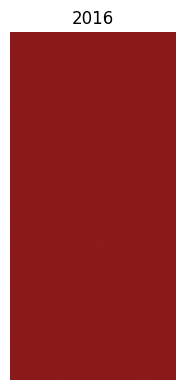

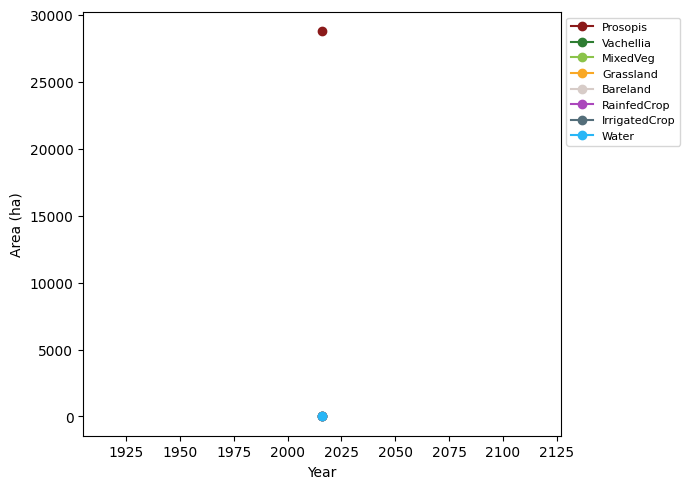

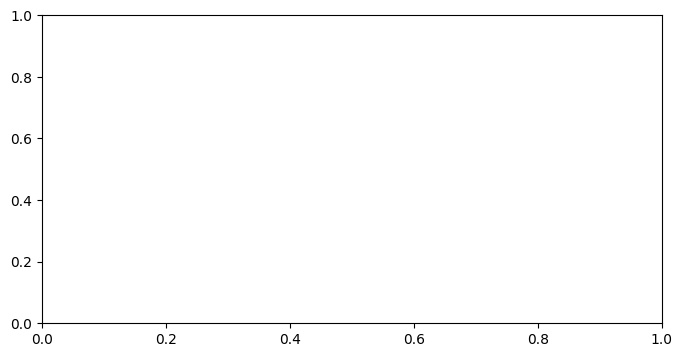

In [32]:
COLORS = ["#8B1A1A", "#2E7D32", "#8BC34A", "#F9A825",
          "#D7CCC8", "#AB47BC", "#546E7A", "#29B6F6"]  # Prosopis, Vachellia, MixedVeg, Grassland, Bareland, RainfedCrop, IrrigatedCrop, Water
CLASS_TO_INT = {c: i for i, c in enumerate(CLASSES)}
cmap = mcolors.ListedColormap(COLORS)

# --- Figure 2 equivalent: classified maps side by side ---
years = sorted(classified)
fig, axes = plt.subplots(1, len(years), figsize=(4 * len(years), 4))
for ax, y in zip(np.atleast_1d(axes), years):
    int_map = np.vectorize(lambda v: CLASS_TO_INT.get(v, -1))(classified[y])
    ax.imshow(int_map, cmap=cmap, vmin=0, vmax=len(CLASSES) - 1)
    ax.set_title(str(y)); ax.axis("off")
fig.tight_layout()

# --- Figure 3A equivalent: area trend per class ---
fig, ax = plt.subplots(figsize=(7, 5))
for cls, color in zip(CLASSES, COLORS):
    ax.plot(years, area_tab.loc[cls, years], marker="o", label=cls, color=color)
ax.set_xlabel("Year"); ax.set_ylabel("Area (ha)")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()

# --- Figure 4 equivalent: net change per interval, grouped bars ---
fig, ax = plt.subplots(figsize=(8, 4))
net_tab.plot(kind="bar", ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Net change (ha)"); ax.set_xlabel("LULC class")
fig.tight_layout()

# --- Figure 5 equivalent: Sankey of class transitions across all time steps ---
node_labels, node_index = [], {}
for y in years:
    for cls in CLASSES:
        node_index[(y, cls)] = len(node_labels)
        node_labels.append(f"{cls} {y}")

src, tgt, val = [], [], []
for y1, y2 in zip(years[:-1], years[1:]):
    tm = transition_matrix(classified[y1], classified[y2])
    for c1 in CLASSES:
        for c2 in CLASSES:
            v = tm.loc[c1, c2]
            if v > 0:
                src.append(node_index[(y1, c1)]); tgt.append(node_index[(y2, c2)]); val.append(float(v))

node_colors = [COLORS[CLASS_TO_INT[lbl.rsplit(' ', 1)[0]]] for lbl in node_labels]
sankey = go.Figure(go.Sankey(
    node=dict(label=node_labels, color=node_colors, pad=8, thickness=12),
    link=dict(source=src, target=tgt, value=val),
))
sankey.update_layout(title="LULC transitions across time steps", font_size=9)
sankey.show()


## 10. Where to take this next

- **Get Option A working first.** If the paper's supplementary reference
  tables are usable coordinates, swap them in for 1988/2002/2016 and this
  stops being a toy, a genuine independent replication.
- **Add back 1995 and 2009** once the labeling workflow is solid, to match
  the paper's full 5-point series.
- **For the current step**, the red-edge bands (`B5`/`B6`/`B7`) and derived
  indices (VARI, RVI) from the 2026 Sentinel-2 follow up study are a real,
  citable upgrade over the original 2019 Landsat-only feature set — worth
  adding to `S2_BANDS` above once you're past the basic version.
- Kenya's *National Strategy and Action Plan for Prosopis 2023-2032*
  relevant policy context if this heads toward the biochar/carbon-removal
  angle.


,2016
Prosopis,28748.52
NotProsopis,65606.85


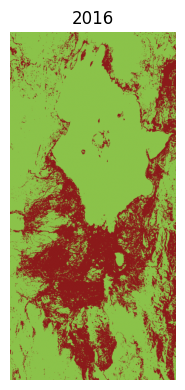

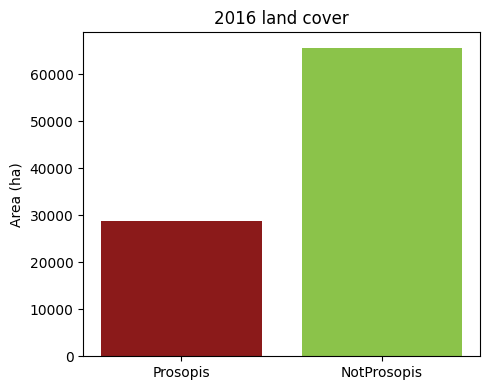

In [34]:
CLASSES = ["Prosopis", "NotProsopis"]  # matches what you actually trained on
PIXEL_HA = (30 * 30) / 10_000  # ha per pixel at 30 m

def area_table(classified, pixel_ha=PIXEL_HA):
    years = sorted(classified)
    tab = pd.DataFrame({y: pd.Series(classified[y].ravel()).value_counts() for y in years}).fillna(0)
    return tab.reindex(CLASSES).fillna(0) * pixel_ha

COLORS = ["#8B1A1A", "#8BC34A"]  # Prosopis, NotProsopis
CLASS_TO_INT = {c: i for i, c in enumerate(CLASSES)}
cmap = mcolors.ListedColormap(COLORS)

# --- classified map ---
years = sorted(classified)
fig, axes = plt.subplots(1, len(years), figsize=(4 * len(years), 4))
for ax, y in zip(np.atleast_1d(axes), years):
    int_map = np.vectorize(lambda v: CLASS_TO_INT.get(v, -1))(classified[y])
    ax.imshow(int_map, cmap=cmap, vmin=0, vmax=len(CLASSES) - 1)
    ax.set_title(str(y)); ax.axis("off")
fig.tight_layout()

# --- area by class -- a trend line needs >=2 points; a bar is the honest single-year version ---
area_tab = area_table(classified)
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(area_tab.index, area_tab[years[0]], color=COLORS)
ax.set_ylabel("Area (ha)"); ax.set_title(f"{years[0]} land cover")
fig.tight_layout()

area_tab

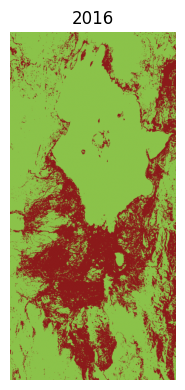

In [33]:
CLASSES = ["Prosopis", "NotProsopis"]
COLORS = ["#8B1A1A", "#8BC34A"]
CLASS_TO_INT = {c: i for i, c in enumerate(CLASSES)}
cmap = mcolors.ListedColormap(COLORS)

years = sorted(classified)
fig, axes = plt.subplots(1, len(years), figsize=(4 * len(years), 4))
for ax, y in zip(np.atleast_1d(axes), years):
    int_map = np.vectorize(lambda v: CLASS_TO_INT.get(v, -1))(classified[y])
    ax.imshow(int_map, cmap=cmap, vmin=0, vmax=len(CLASSES) - 1)
    ax.set_title(str(y)); ax.axis("off")
fig.tight_layout()